# Part A — Build and compare neural networks

In [12]:
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split

# Ensures results are reproducible
keras.utils.set_random_seed(42)

# Load Fashion-MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
_, counts = np.unique(y_train, return_counts=True)
print("Value counts of y_train:", counts)

# Normalize pixel values to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten 28 x 28 images into 784 features
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Splitting training data into training and validation subsets.
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42
)

Value counts of y_train: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


## Task 1 – Build a baseline model
Build a baseline model with one hidden layer of 32 neurons using ReLU activation and the Adam optimizer. Train it and record its training and validation accuracy.

In [4]:
def create_and_fit_model(hidden_neurons: int, hidden_activation, optimizer: str) -> tuple[keras.Sequential, keras.callbacks.History]:
    model = keras.Sequential(
        [
            keras.Input(
                shape=(784,)
            ),  # One feature for each pixel in a 28 × 28 image.
            keras.layers.Dense(
                hidden_neurons, activation=hidden_activation,
            ),  # x hidden neurons; nonlinear transformations.
            keras.layers.Dense(
                10, activation=keras.activations.softmax
            ),  # One output probability per fashion category, summing to 1.
        ]
    )

    model.compile(
        loss=keras.losses.sparse_categorical_crossentropy,  # What counts as error
        optimizer=optimizer,  # How weights update
        metrics=[
            keras.metrics.SparseCategoricalAccuracy()
        ],  # What performance to report
    )

    history = model.fit(
        x_train,
        y_train,
        epochs=10,
        batch_size=64,
        verbose=0,
        validation_data=(x_val, y_val),
    )

    return model, history

baseline_model, base_hist = create_and_fit_model(32, keras.activations.relu, keras.optimizers.Adam())

print(f"Baseline Training Accuracy: {base_hist.history['sparse_categorical_accuracy'][-1]:.4f}")
print(f"Baseline Validation Accuracy: {base_hist.history['val_sparse_categorical_accuracy'][-1]:.4f}")

Baseline Training Accuracy: 0.8876
Baseline Validation Accuracy: 0.8692


## Task 2 – Run experiments 
Starting from the baseline, run three more experiments. For each experiment, change only the setting shown below; keep the other settings the same as the baseline.

| Model | Hidden neurons | Hidden activation | Optimizer |
| --- | --- | --- | --- |
| Baseline | 32 | ReLU | Adam |
| Experiment 1 | 64 | ReLU | Adam |
| Experiment 2 | 32 | tanh | Adam |
| Experiment 3 | 32 | ReLU | SGD |

In [5]:
exp_1_model, exp_1_hist = create_and_fit_model(64, keras.activations.relu, keras.optimizers.Adam())
exp_2_model, exp_2_hist = create_and_fit_model(32, keras.activations.tanh, keras.optimizers.Adam())
exp_3_model, exp_3_hist = create_and_fit_model(32, keras.activations.relu, keras.optimizers.SGD())

## Task 3 – Record -> identify -> evaluate
Record the training and validation accuracy of all four models in a results table. Identify the model with the highest validation accuracy. Evaluate that model on the test set and report its test accuracy. Do not use the test set to choose the model.

In [6]:
history_list = [base_hist, exp_1_hist, exp_2_hist, exp_3_hist]
model_names = ['Baseline', 'Experiment 1', 'Experiment 2', 'Experiment 3']

data = []
for name, hist in zip(model_names, history_list):
    h = hist.history 
    data.append({
        'Model': name,
        'Train Accuracy': h['sparse_categorical_accuracy'][-1],
        'Val Accuracy': h['val_sparse_categorical_accuracy'][-1],
    })


print(pd.DataFrame(data).to_string(index=False))

       Model  Train Accuracy  Val Accuracy
    Baseline        0.887646      0.869167
Experiment 1        0.898812      0.880500
Experiment 2        0.895542      0.875250
Experiment 3        0.846375      0.840083


**Experiment 1** has the highest validation accuracy with an accuracy of **88.1%**

In [7]:
print("Test accuracy:", exp_1_model.evaluate(x_test, y_test, verbose=0)[1])

Test accuracy: 0.8705999851226807


# Part B — Explain your neural network

> **Q1. Architecture and parameters.** For the baseline model (784 inputs, 32 hidden neurons and 10 outputs), calculate the number of trainable weights and biases. Explain the difference between a parameter and a hyperparameter.


`Weights = Number of Inputs * Number of Neurons`

`Biases = Number of Neurons (one bias per neuron)`

In [8]:
hidden_layer_weights = 784 * 32
hidden_layer_biases = 32
output_layer_weights = 32 * 10
output_layer_biases = 10

total_weights = hidden_layer_weights + output_layer_weights
total_biases = hidden_layer_biases + output_layer_biases
total = total_weights + total_biases

print(f"Total number of trainable weights ({total_weights}) and biases ({total_biases}) for the baseline model: {total}")

Total number of trainable weights (25408) and biases (42) for the baseline model: 25450


Parameters are the model’s learned values, which it uses to make predictions. They are updated during training. Hyperparameters are chosen configuration options for the model before training, like number of hidden neurons, hidden activation function and optimizer.

>**Q2. Activation and loss.** Why do we use ReLU in the hidden layer and softmax in the output layer? Why is sparse categorical cross-entropy appropriate for this dataset?

We use ReLU in the hidden layer to break the linear prediction lines created by only adding the weights together, making the model find more complex patterns. Softmax in the output layer transforms the outputted scores into percentages that add up to 100%. This is used in the loss function "sparse categorical cross-entropy". This loss function is appropriate because it outputs a large error/loss for confidently wrong predictions, and a smaller error the more confident it is in the right answer. It is also appropriate because it expects an integer target (fashion category).

>**Q3. Training and Keras functions.** Explain the purposes of model.compile(), model.fit(), model.evaluate() and model.predict(). Briefly explain what backpropagation and the optimizer do during training.

**model.compile()**: Configures the model for training by setting its loss function, optimizer and metrics to report.

**model.fit()**: Trains the model on the training data for a fixed number of iterations (epochs). It executes the core training loop: *initialization -> forward pass -> measure loss -> backpropagation -> optimization (-> repeat from forward pass*)

**model.evaluate()**: Calculates the loss and the model metrics (such as accuracy) using a test set and its true target.

**model.predict()**: Predicts the target for the input samples.

Backpropagation calculates the gradients of loss with respect to the weights, starting with the weights closest to the output and moving backwards using the Chain rule. The optimizer uses the gradients to move the weights in the opposite direction of the gradients, lowering the loss.

>**Q4. Interpreting your experiments.** Which model achieved the highest validation accuracy? Did changing
the number of neurons, activation function or optimizer always improve accuracy? Explain using your results.

Experiment 1 achieved the highest validation accuracy of 88.1% (1.1pp higher than baseline). Doubling the number of neurons produced the largest improvement. Experiment 2 changed the activation function from ReLU to tanh. This also increased its accuracy slightly to 87.5% (0.6pp higher than baseline). Experiment 3 changed the optimizer from Adam to SGD. This worsened the accuracy to 84.0% (2.9pp lower than baseline).

The baseline model got a validation accuracy of **86.9%**. The table below shows each experiment’s validation accuracy change relative to the baseline.
| Model | Hyperparameter | Change | Difference |
| --- | --- | --- | --- |
| Experiment 1 | Number of neurons | 32 -> 64 | +1.1pp |
| Experiment 2 | Activation function | ReLU -> tanh | +0.6pp |
| Experiment 3 | Optimizer | Adam -> SGD  | -2.9pp |


# Part C — Understand classification errors
Generate a confusion matrix for your selected model using the test data. Identify one pair of clothing categories the model confuses. Explain in 2–3 sentences what the confusion matrix shows that overall accuracy does not.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


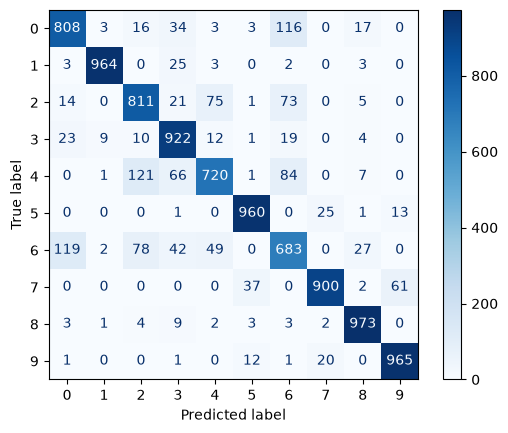

In [22]:
y_probs = exp_1_model.predict(x_test)
y_pred = np.argmax(y_probs, axis=1)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()

The class labels are from the [Keras documentation](https://keras.io/api/datasets/fashion_mnist/).

The two biggest fashion category confusions shown in the matrix are:
- The model has a tendency to confuse category 6 (Shirt) for category 0 (T-shirt/top) in both directions.
- It also mistakes category 4 (Coat) for category 2 (Pullover), but not as much the other way around.

The accuracy gives you a single overall metric of how often the model predicts correctly, but it hides specific flaws. 